# Example 3.5: Effect of Mutation Probability on Convergence
**Chapter 3 · Four Bar Mechanisms with Genetic Algorithms**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Statement
Evaluate the impact of five mutation probability values $P_m \in \{0.01,\,0.05,\,0.10,\,0.20,\,0.40\}$ on the convergence of the GA applied to $f(x)=(x-3.7)^2+0.5\,\sin(5x)$. Use `n_pop=40`, `n_gen=80`, and a fixed seed `seed=99`.

**Objective:** Identify the optimal range of $P_m$ and the effect of over-exploration (excessive mutation) vs. premature convergence.

In [1]:
# ── Imports─────────────────────────────────────────────────────────
from numpy import *
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.size': 12})

In [2]:
# ── Objective function──────────────────────────────────────────────────────
def f_obj(x):
    return (x - 3.7)**2 + 0.5 * sin(5 * x)

def ga_pm(pm_val, seed=99, n_pop=40, n_gen=80):
    """GA with mutation probability pm_val. Returns (hist, x*, f*)."""
    rng = random.default_rng(seed)
    pop = rng.uniform(0, 10, n_pop)
    hist = []
    for _ in range(n_gen):
        fit = array([f_obj(x) for x in pop])
        hist.append(fit.min())
        padres = []
        for __ in range(n_pop):
            cands = rng.choice(n_pop, 3, replace=False)
            padres.append(pop[cands[argmin(fit[cands])]])
        padres = array(padres)
        hijos = []
        for i in range(0, n_pop - 1, 2):
            a = rng.uniform(0, 1)
            hijos += [a*padres[i]+(1-a)*padres[i+1],
                       (1-a)*padres[i]+a*padres[i+1]]
        pop = clip(array(hijos[:n_pop]), 0, 10)
        mask = rng.random(n_pop) < pm_val
        pop[mask] += rng.normal(0, 0.4, int(mask.sum()))
        pop = clip(pop, 0, 10)
    bx = pop[argmin(array([f_obj(x) for x in pop]))]
    return array(hist), bx, f_obj(bx)

# ── Experiment───────────────────────────────────────────────────────────
pm_vals   = [0.01, 0.05, 0.10, 0.20, 0.40]
resultados = {}
for pm in pm_vals:
    hist, bx, bf = ga_pm(pm)
    resultados[pm] = (hist, bx, bf)
    print(f"Pm={pm:.2f}:  x*={bx:.4f}  f(x*)={bf:.4f}  "
          f"hist[0]→hist[-1]= {hist[0]:.3f}→{hist[-1]:.3f}")



Pm=0.01:  x*=3.4896  f(x*)=-0.4486  hist[0]→hist[-1]= -0.448→-0.449
Pm=0.05:  x*=3.4901  f(x*)=-0.4486  hist[0]→hist[-1]= -0.448→-0.449
Pm=0.10:  x*=3.4896  f(x*)=-0.4486  hist[0]→hist[-1]= -0.448→-0.449
Pm=0.20:  x*=3.4896  f(x*)=-0.4486  hist[0]→hist[-1]= -0.448→-0.449
Pm=0.40:  x*=3.4896  f(x*)=-0.4486  hist[0]→hist[-1]= -0.448→-0.449


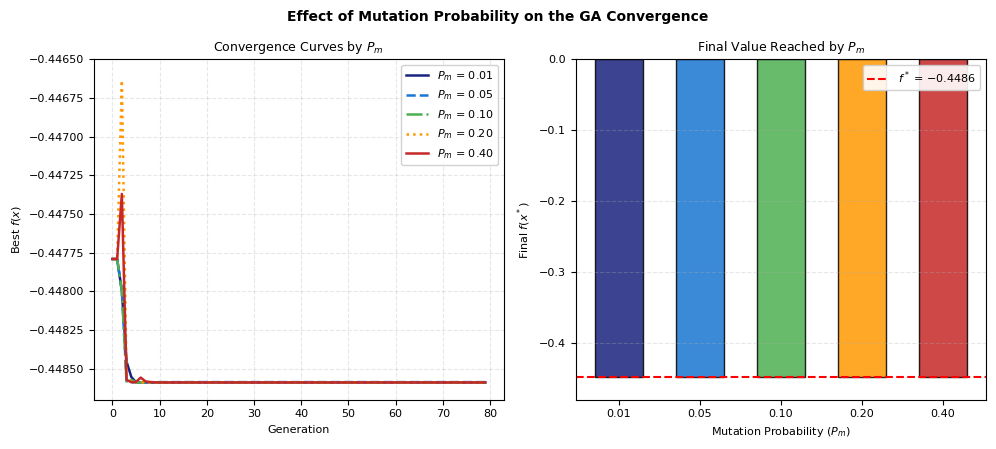

In [4]:
import os
import glob
import matplotlib.pyplot as plt

# ── System for dynamic filename configuration ──
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_3.5_mutation_probability_effect"
except Exception:
    notebook_name = "Figure_3.5_mutation_probability_effect"

# ── Springer Global Settings ──
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Helvetica', 'Arial'],
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8
})

colores = ['#1a237e', '#1976D2', '#4CAF50', '#FF9800', '#C62828']
lineas  = ['-', '--', '-.', ':', '-']

# ── Create Figure ──
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

# Left Plot: Convergence Curves
for pm, col, ls in zip(pm_vals, colores, lineas):
    ax1.plot(resultados[pm][0], color=col, ls=ls, lw=1.8, label=f'$P_m$ = {pm:.2f}')

ax1.set_xlabel('Generation')
ax1.set_ylabel('Best $f(x)$')
ax1.set_title('Convergence Curves by $P_m$')
# Expand y-lim slightly to give space to the legend
ax1.set_ylim(-0.4487, -0.4465)
ax1.legend(loc='upper right', frameon=True, framealpha=0.9)
ax1.grid(True, linestyle='--', alpha=0.3)

# Right Plot: Final Value Reached
f_finales = [resultados[pm][2] for pm in pm_vals]
bars = ax2.bar(range(len(pm_vals)), f_finales, color=colores, edgecolor='k', alpha=0.85, width=0.6)
ax2.axhline(-0.4486, color='red', ls='--', lw=1.5, label='$f^*$ = −0.4486')

ax2.set_xticks(range(len(pm_vals)))
ax2.set_xticklabels([f'{p:.2f}' for p in pm_vals])
ax2.set_xlabel('Mutation Probability ($P_m$)')
ax2.set_ylabel('Final $f(x^*)$')
ax2.set_title('Final Value Reached by $P_m$')
# Ensure appropriate spacing to make the horizontal line clear
ax2.set_ylim(-0.48, 0.0)
ax2.legend(loc='upper right', frameon=True, framealpha=0.9)
ax2.grid(axis='y', linestyle='--', alpha=0.3)

plt.suptitle('Effect of Mutation Probability on the GA Convergence', fontsize=10, fontweight='bold', y=0.98)
plt.tight_layout()

# ── Double Exportation ──
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()